# Multi-Class Logistic Regression for Strong Lensing

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 8 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In Chapter 7, we developed the mathematical description of binary classification with logistic regression. It separates two classes with the sigmoid function and gradient descent. We now extend these concepts to multi-class classification, where we must distinguish among many classes. This situation often arises in astronomy.

This tutorial studies multi-class logistic regression with strong gravitational lensing. The curvature of spacetime near a massive foreground object deflects the light of a distant galaxy, as general relativity predicts. The geometry of the lens and the source decides the pattern. It can be multiple images of the same galaxy, giant arcs, complete Einstein rings or short radial arcs near the center of the lens. Such lenses map the dark matter of galaxy clusters and magnify galaxies of the early universe. The time delays between multiple images also measure cosmological parameters.

The James Webb Space Telescope (JWST) changed the study of strong lensing. With its segmented primary mirror of 6.5 meters and its infrared instruments, JWST reaches an angular resolution of about 0.1 arcseconds in the near-infrared. This is enough to resolve individual star-forming regions in lensed galaxies at cosmic noon, the epoch of peak star formation in the universe. A single deep field can contain dozens of lensing features, such as arcs of different curvature, multiple images and partial Einstein rings. Classification by eye is not practical for large surveys, so we need automatic methods that distinguish between different types of objects.

In this tutorial, we build a complete multi-class classification pipeline, from cutouts of JWST images to the evaluation of the classes. A human or a vision-language model can label an image, but this is slow and costly for every new image. We ask whether a classifier can learn the labels from the features of labeled images and give the same labels to new images. The step from binary to multi-class classification shows how machine learning concepts extend to more complex problems, while the computation stays tractable.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial uses the concepts of Chapter 7 and assumes the following.

- Binary logistic regression, with the sigmoid function and gradient descent
- The cross-entropy loss and its probabilistic interpretation
- The evaluation of a binary classifier with the confusion matrix, the recall and the precision
- The gradient of a loss function and its use in optimization
- NumPy operations such as matrix multiplication, broadcasting and array manipulation
- Python programming and vectorized computations

### Learning Objectives

After this tutorial you can do the following.

- Extend binary classification to many classes with the softmax function and the multi-class cross-entropy loss
- Convert images into numerical features with a pre-trained neural network
- Implement the softmax function in a numerically stable way
- Implement stochastic gradient descent with mini-batches
- Choose the learning rate and the weight decay on validation objects and score the model on test objects
- Build and read a confusion matrix, compute the precision and the recall of each class and find systematic confusions between classes

These skills are the basis of classification pipelines for large surveys.

We begin by importing the libraries and setting the plot style.

In [1]:
# Packages for the arrays, the table, the plots and the images
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
import pickle

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Set random seed for reproducibility
np.random.seed(42)

%matplotlib inline

## A JWST Observation of Strong Lensing

We begin with an example of a JWST observation of strong lensing.

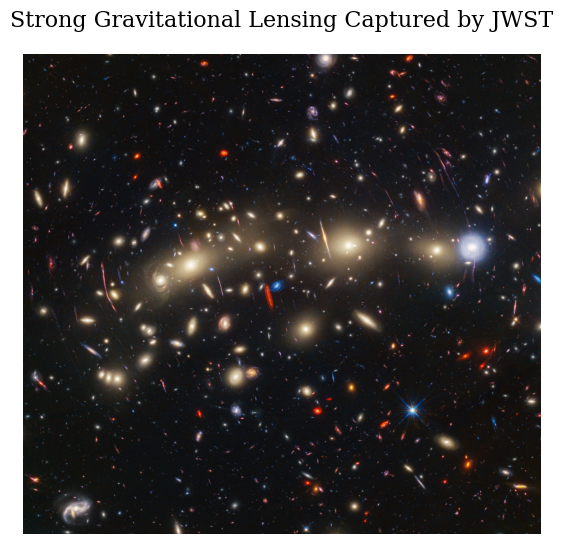

In [2]:
# Load and display a JWST strong lensing image
img = Image.open('../data/dataset_jwst.png')

# Show the image without axes
plt.figure(figsize=(6.2, 5.7))  # a photograph, shown at its original size
plt.imshow(img)
plt.axis('off')
plt.title('Strong Gravitational Lensing Captured by JWST', pad=20)
plt.tight_layout()
plt.show()

## Data Preparation: From Raw Images to Machine Learning Input

Raw astronomical images are difficult to use in machine learning. A single JWST deep field contains thousands of objects at different distances, with very different angular sizes, surface brightnesses and morphologies. Earlier approaches needed us to identify and extract the regions of interest manually, which does not scale to modern surveys.

For this tutorial, we preprocessed our JWST images with the Segment Anything Model (SAM), which Meta AI Research developed. SAM learned from more than 1 billion masks, which mark the pixels of an object, to find objects in many domains. It separates the objects of an astronomical image and makes precise masks around extended, irregular objects. The segmentation turns a complex field into individual cutouts, and each cutout contains a possible object of interest. A hard image analysis problem thus becomes a classification task in which each cutout belongs to a class.

We assembled a dataset of segmented objects from public JWST observations, and we preprocessed each object to make the data consistent.

- **Standardized size.** All images have 64×64 pixels, which balances the detail that we keep against the computing time.
- **Labeling.** Vision-language models, which process images and text, described each class and gave initial ratings of how likely its objects contain gravitational arcs.

We now load the preprocessed data.

In [3]:
# Load the preprocessed strong lensing dataset
import zipfile
import warnings
with zipfile.ZipFile('../data/dataset_jwst.pkl.zip', 'r') as zip_ref:
    with zip_ref.open('dataset_jwst.pkl', 'r') as f:
        # Numpy warns that the file comes from an older version. The warning is harmless.
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', DeprecationWarning)
            images_df = pickle.load(f)

# Rename the columns of the file to the names that we use below
images_df = images_df.rename(columns={
    'image_resized': 'image',
    'cluster': 'label',
    'concise_description': 'description',
    'contains_gravitational_arcs': 'arc_rating'
})

# Convert the arc ratings to numbers
images_df['arc_rating'] = pd.to_numeric(images_df['arc_rating'], errors='coerce')

# Count the objects and the classes
print(f"Objects = {len(images_df)}, classes = {images_df['label'].nunique()}")

Objects = 2873, classes = 50


The data have four components.

- **Image.** A 64×64×3 RGB image array for each object. The size is the same for all objects, which gives a consistent input for our machine learning pipeline.
- **Class.** An analysis of the image features grouped the objects into classes of similar appearance, numbered from 0. The classes may correspond to different lensing configurations, galaxy morphologies or image artifacts.
- **Description.** A short text summarizes the appearance of each class.
- **Gravitational arc confidence.** A rating from 1 to 5 shows how likely it is that the objects of a class contain gravitational arcs. A rating of 1 means definitely no arcs, 3 means uncertain and 5 means definitely arcs.

The description and the rating belong to the class and not to the single object. The labels are not perfect. They stand in for a visual inspection by a human, so the accuracy below measures the agreement with these labels.

We use the classes as the classification targets, and we use the arc ratings to understand the astrophysical meaning of the classes. To see what we work with, we now show five random objects for each of five classes. We choose the classes from different parts of the list sorted by arc rating. We label each row with the class, its rating and its description.

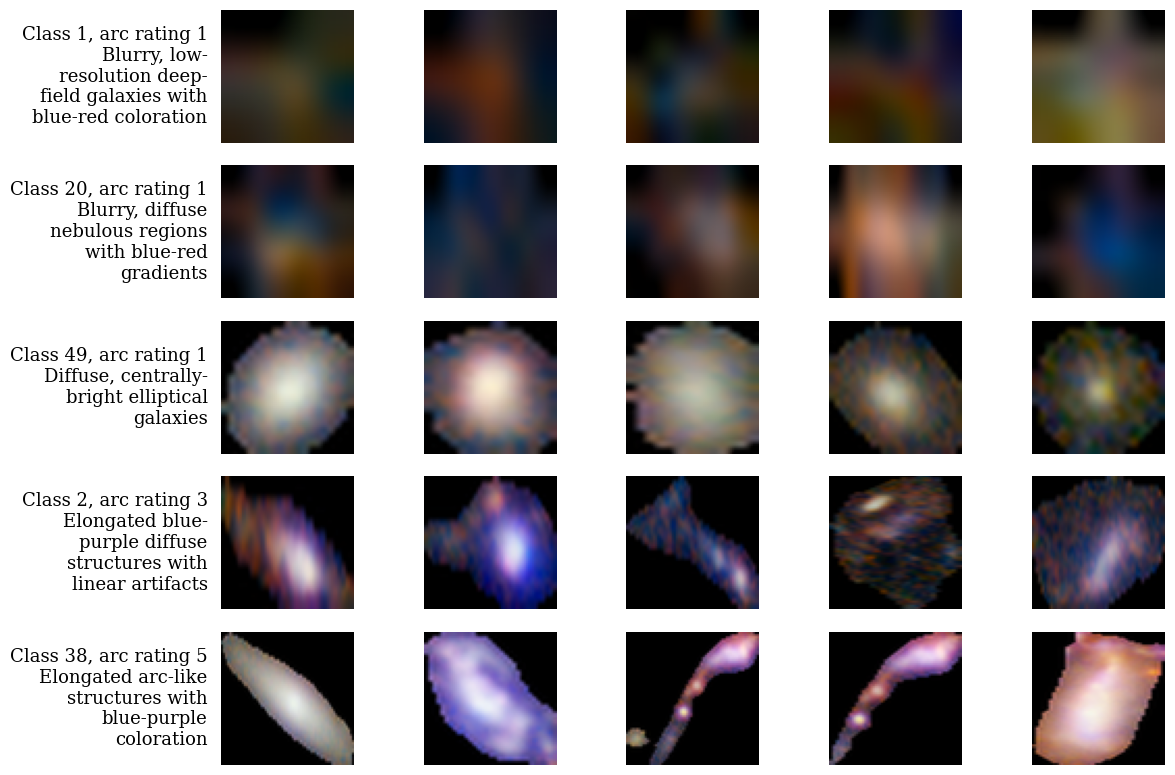

In [4]:
import textwrap

# Sort the classes by their arc rating and take five classes from different parts of the list
class_ratings = [(c, images_df.loc[images_df['label'] == c, 'arc_rating'].mean())
                 for c in images_df['label'].unique()]
class_ratings.sort(key=lambda pair: pair[1])
n_classes = len(class_ratings)
selected_classes = [class_ratings[i][0] for i in
                    [0, n_classes // 4, n_classes // 2, 3 * n_classes // 4, -1]]

# Show five random objects of each class
fig, axes = plt.subplots(5, 5, figsize=(12.8, 8.0))
for i, class_id in enumerate(selected_classes):
    class_data = images_df[images_df['label'] == class_id]

    # Five random objects of the class, with a fixed seed
    samples = class_data.sample(5, random_state=0)
    for j, (_, row) in enumerate(samples.iterrows()):
        axes[i, j].imshow(row['image'])
        axes[i, j].axis('off')

    # The rating and the description are the same for all objects of a class
    description = textwrap.fill(class_data['description'].iloc[0], 20)
    axes[i, 0].text(-0.1, 0.5,
                    f"Class {class_id}, arc rating {class_data['arc_rating'].iloc[0]:.0f}\n{description}",
                    transform=axes[i, 0].transAxes, fontsize=13,
                    verticalalignment='center', horizontalalignment='right')

plt.tight_layout()
plt.subplots_adjust(right=0.98)
plt.show()

Objects of one class look alike, and the arc rating changes from the blurry background patches to the elongated galaxies with bright cores. This is what the classifier must learn to tell apart.

## From Pixels to Features: Numerical Representations of Images

Our 64×64 RGB images contain 12,288 pixel values (64 × 64 × 3). Raw pixels as features for classification have several basic problems. A model with more than 12,000 features needs much memory and computing time. A small translation or rotation changes the pixel values a lot, while the identity of the object stays the same. Pixels also do not represent higher-level concepts such as edges, textures or shapes, so a model needs very large training sets to learn them.

Modern computer vision solves this problem with deep neural networks that train on very large sets of images and learn hierarchical representations. The early layers capture edges, corners and simple textures. The later layers capture more complex shapes and the semantic concepts that matter for object recognition. We can use such a pre-trained network as a feature extractor, which is transfer learning. We pass our images through the network and take the output of one of the later layers. This gives compact numerical representations, called embeddings, typically with 512 to 2048 dimensions.

Pre-trained networks did not train on astronomical images, but the visual features that they learned transfer to our domain. These features detect curves, gradients, symmetries and complex shapes. Strong lensing features such as arcs and rings have geometric properties in common with everyday curved objects, so the networks give meaningful representations.

We use the pre-trained model `clip-ViT-B-32`, which Hugging Face provides through the sentence-transformers library. It is a Vision Transformer that was trained with the technique CLIP (Contrastive Language-Image Pre-training) on pairs of images and text. An image and its description then get similar embeddings, as in cross-modal learning. The embeddings therefore encode both the visual appearance and the semantic meaning. We now implement the feature extraction.

In [5]:
# Install required packages for feature extraction
import sys
import subprocess
import importlib

# Pairs of the package name for pip and the module name for import
required_packages = [('torch', 'torch'), ('sentence-transformers', 'sentence_transformers')]
for pip_name, import_name in required_packages:
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name, "--quiet"])
        print(f"{pip_name} installed successfully!")

import torch
from sentence_transformers import SentenceTransformer

# Switch off the progress bars and the token warning of the model download
from transformers.utils import logging as hf_logging
from huggingface_hub import logging as hub_logging
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()

# Convert the image arrays to PIL images, which the model requires
pil_images = [Image.fromarray(img.astype('uint8')) for img in images_df['image']]

# Load the pre-trained CLIP model and convert the images to embeddings in batches
model = SentenceTransformer('clip-ViT-B-32')
batch_size = 32
embeddings_list = []
for i in range(0, len(pil_images), batch_size):
    # Extract embeddings with no gradient computation (inference only)
    with torch.no_grad():
        embeddings_list.extend(model.encode(pil_images[i:i + batch_size], show_progress_bar=False))
images_df['embedding'] = embeddings_list

# Compare the number of embedding values with the number of pixel values
embedding_dim = len(embeddings_list[0])
n_pixels = images_df['image'].iloc[0].size
print(f"Each image: {n_pixels:,} pixel values, {embedding_dim} embedding values, "
      f"ratio {n_pixels / embedding_dim:.0f}:1")

Each image: 12,288 pixel values, 512 embedding values, ratio 24:1


## Visualizing the Embedding Space

Our image embeddings live in a 512-dimensional space. We cannot visualize this space directly, but it contains rich structure that organizes the images by their visual and semantic properties. To see how the images relate to each other in this space, we map the data to 2D and try to keep the important relationships.

Principal component analysis (PCA) is a common linear method for such a map. For complex, high-dimensional data such as image embeddings, nonlinear methods often preserve the local structure better. We use UMAP (Uniform Manifold Approximation and Projection), a nonlinear dimensionality reduction method. It preserves both the local neighborhood structure and the global structure. Similar images in the 512-dimensional embedding space should appear near each other in the 2D map.

If the embeddings relate to the presence of arcs, we expect a gradient from low to high ratings. We also expect a separation of the objects with no arcs from the objects with definite arcs. We first compute the map.

In [6]:
# Install UMAP if needed
try:
    import umap
except ImportError:
    print("Installing UMAP for dimensionality reduction...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "umap-learn", "--quiet"])
    import umap
    print("UMAP installed successfully!")

# Give each embedding feature zero mean and unit variance
embeddings = np.array(images_df['embedding'].tolist())
embeddings_scaled = (embeddings - embeddings.mean(axis=0)) / embeddings.std(axis=0)

# Compute two UMAP coordinates for each object. A fixed seed makes the map repeatable, and UMAP then runs on one thread.
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric='cosine',
    random_state=42,
    n_jobs=1,
    verbose=False
)

# Fit the map and keep the two coordinates of each object
umap_x, umap_y = reducer.fit_transform(embeddings_scaled).T

Each point of the map is one object. We first color the five classes of the gallery and draw all other objects in grey, because 50 colors are not readable.

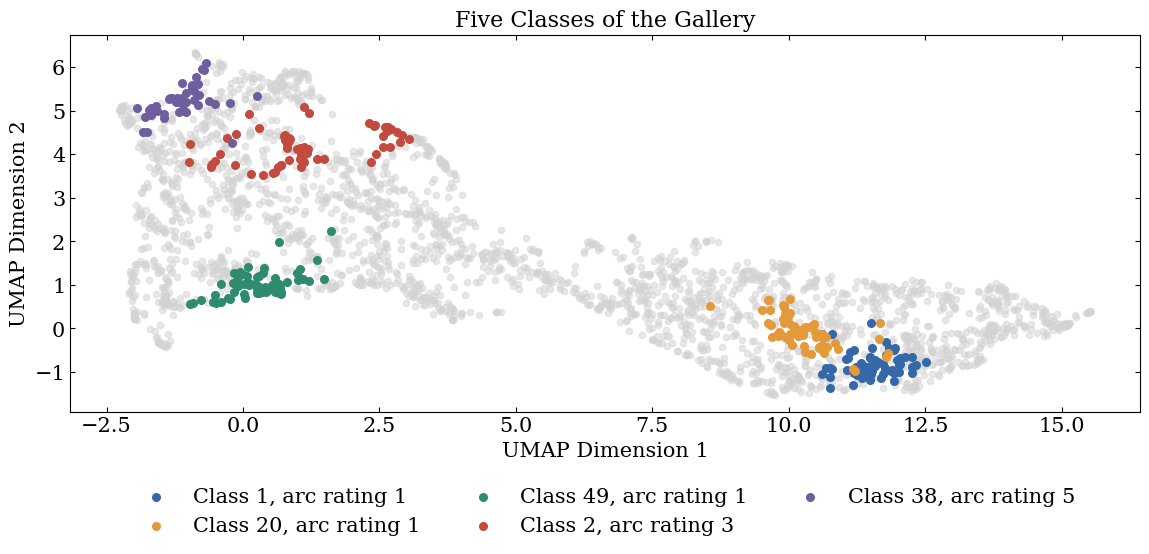

In [7]:
# Draw all objects in grey and the five classes of the gallery in color
plt.figure(figsize=(13.8, 4.9))
plt.scatter(umap_x, umap_y, color='lightgray', alpha=0.5, s=20)
for class_id, color in zip(selected_classes, ['C0', 'C1', 'C2', 'C3', 'C4']):
    in_class = (images_df['label'] == class_id).to_numpy()
    rating = images_df.loc[in_class, 'arc_rating'].iloc[0]
    plt.scatter(umap_x[in_class], umap_y[in_class], color=color, s=30,
                label=f'Class {class_id}, arc rating {rating:.0f}')

# Label the axes, add the title, and the legend
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.title('Five Classes of the Gallery')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

**Grouping by visual properties.** Objects of one class lie close together. The five classes of the gallery occupy different regions, except that classes 1 and 20 lie side by side. The grey objects show that other classes overlap, so the map does not separate all of them. A map in two dimensions loses information, and the classification below tests how well the features separate the classes.

The classes alone do not tell us the astrophysical meaning of the groups, so we color the same map by the gravitational arc rating. We also overlay image thumbnails, framed in the color of their rating, which show directly which types of objects occupy different regions.

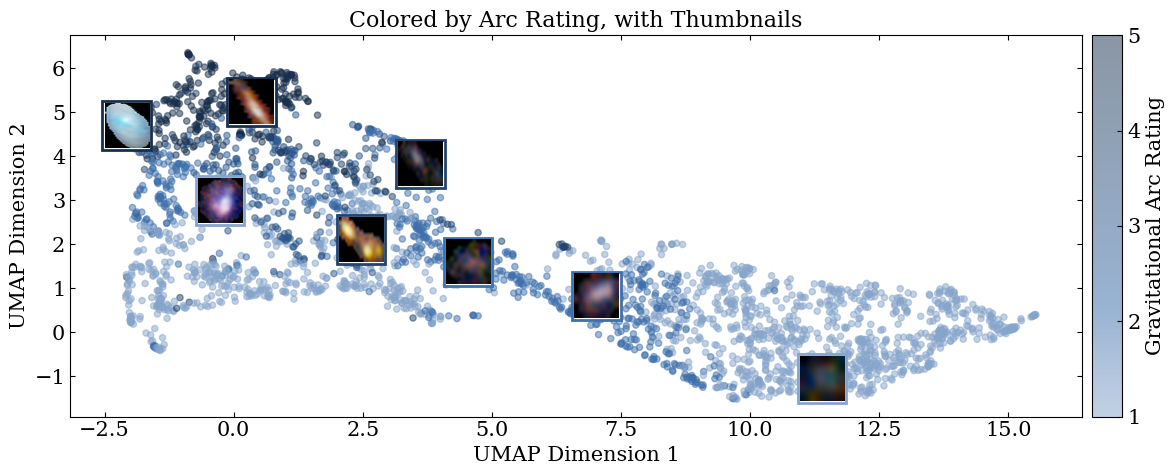

In [8]:
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(12.0, 5.0))

# Points colored by arc rating (the blue map without its white end), with a colorbar of the height of the panel
scatter = ax.scatter(umap_x, umap_y, c=images_df['arc_rating'], cmap=plt.matplotlib.colors.ListedColormap(plt.colormaps['book_blue'](np.linspace(0.3, 1, 256))),
                     alpha=0.5, s=20, vmin=1, vmax=5)
cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.1)
cbar = plt.colorbar(scatter, cax=cax)
cbar.set_label('Gravitational Arc Rating')
cbar.set_ticks([1, 2, 3, 4, 5])

# Choose two random objects of each arc rating that lie at least 2 map units from the other thumbnails
umap_xy = np.column_stack([umap_x, umap_y])
rng = np.random.default_rng(0)
chosen = []
count = {rating: 0 for rating in range(1, 6)}
for position in rng.permutation(len(images_df)):
    rating = images_df['arc_rating'].iloc[position]
    point = np.array([umap_x[position], umap_y[position]])

    # Accept the object when its rating still needs thumbnails and it is far from the chosen ones
    if count[rating] < 2 and all(np.linalg.norm(point - umap_xy[other]) >= 2 for other in chosen):
        chosen.append(position)
        count[rating] += 1

# Overlay the thumbnails, framed in the color of their rating
for position in chosen:
    rating = images_df['arc_rating'].iloc[position]
    thumbnail = OffsetImage(images_df['image'].iloc[position], zoom=0.5)
    ax.add_artist(AnnotationBbox(thumbnail, (umap_x[position], umap_y[position]), frameon=True, pad=0.1,
                                 bboxprops=dict(edgecolor=plt.colormaps['book_blue'](0.3 + 0.7 * (rating - 1) / 4), linewidth=2)))

# Label the axes, add the title
ax.set_xlabel('UMAP Dimension 1')
ax.set_ylabel('UMAP Dimension 2')
ax.set_title('Colored by Arc Rating, with Thumbnails')
plt.tight_layout()
plt.show()

**Gradient in the arc ratings.** The map by arc rating shows a gradient in the embedding space. Objects with high ratings (4 and 5) lie mostly in the upper left. Objects with low ratings (1 and 2) lie in the lower part of the map. This suggests that the pre-trained embeddings encode features that are relevant to lensing. The separation is not perfect, and some overlap exists, in particular for the uncertain objects (rating 3).

**Confirmation with thumbnails.** The thumbnails show that nearby points are objects of similar appearance. Bright elongated structures lie together in one region of the map, and dark blurry patches lie together in another. Objects of intermediate appearance lie between them.

## Multi-class Logistic Regression

With the images transformed into numerical features, we now turn to the classification task. We predict which of the $K = 50$ classes each object belongs to. The model for this problem is multi-class logistic regression (Section 8.3). It extends the binary logistic regression of Chapter 7.

### From Binary to Multi-class: The Softmax Function

In binary classification, the sigmoid function maps a real-valued score to a probability between 0 and 1. For $K$ classes, we need a function that maps $K$ real-valued scores to a probability distribution over all classes. This function is the softmax function (Section 8.4),

$$\text{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}},$$

where $\mathbf{z} = [z_1, z_2, \ldots, z_K]$ are the raw scores, called logits, of the classes. For an object with features $\mathbf{x}$, the logit of class $k$ is the linear prediction $z_k = \mathbf{w}_k^T\mathbf{x}$. The softmax function has three properties.

- All outputs are positive, $\text{softmax}(\mathbf{z})_k > 0$.
- The outputs sum to one, $\sum_{k=1}^{K} \text{softmax}(\mathbf{z})_k = 1$.
- Larger logits give higher probabilities.

### Numerical Stability in Implementation

The softmax function needs a careful implementation to avoid numerical overflow. When the logits are large, $e^{z_k}$ can exceed the limits of floating-point numbers. As in Section 8.8, we use the numerically stable version

$$\text{softmax}(\mathbf{z})_k = \frac{e^{z_k - \max(\mathbf{z})}}{\sum_{j=1}^{K} e^{z_j - \max(\mathbf{z})}}.$$

Subtracting the maximum logit does not change the result, but it prevents overflow. We now code the softmax function and the cross-entropy loss, and we check them on random logits.

In [9]:
def softmax(logits):
    """Compute softmax probabilities from logits, subtracting the maximum logit for numerical stability."""

    # Subtract max for numerical stability
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)

    # Compute exponentials
    exp_logits = np.exp(shifted_logits)

    # Normalize to get probabilities
    probabilities = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

    return probabilities

def to_one_hot(y_true, num_classes):
    """Convert class indices to one-hot rows. Rows that are one-hot already stay as they are."""
    if len(y_true.shape) == 1:
        y_onehot = np.zeros((y_true.shape[0], num_classes))
        y_onehot[np.arange(y_true.shape[0]), y_true] = 1
        return y_onehot
    return y_true

def cross_entropy_loss(y_pred, y_true):
    """Compute the mean categorical cross-entropy loss of predicted probabilities and true labels."""
    batch_size = y_pred.shape[0]
    y_true = to_one_hot(y_true, y_pred.shape[1])

    # Clip predictions to avoid log(0)
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    # Compute cross-entropy
    # Only the true class contributes to the loss for each sample
    loss = -np.sum(y_true * np.log(y_pred)) / batch_size

    return loss

# Check the implementations on random logits for 3 objects and 4 classes
test_logits = np.random.randn(3, 4)
probs = softmax(test_logits)
print("Row sums of the probabilities =", probs.sum(axis=1))
print(f"Cross-entropy loss = {cross_entropy_loss(probs, np.array([0, 2, 1])):.4f}")

Row sums of the probabilities = [1. 1. 1.]
Cross-entropy loss = 1.0040


### Computing Gradients for Optimization

To train our multi-class classifier, we need the gradient of the cross-entropy loss $E$ (Section 8.5) with respect to the weight matrix. For a single training example with feature vector $\mathbf{x}_i$, the gradient with respect to the weight vector of class $k$ is (Section 8.7)

$$\nabla_{\mathbf{w}_k} E = (y_{ik} - t_{ik})\mathbf{x}_i,$$

where $y_{ik}$ is the predicted probability for class $k$ and $t_{ik}$ is the true label, which is 1 for the correct class and 0 otherwise.

For a mini-batch of $M$ examples, we average these gradients. In matrix notation, we compute this efficiently as

$$\nabla_{\mathbf{W}} E = \frac{1}{M}(\mathbf{Y} - \mathbf{T})^T\mathbf{X},$$

where

- $\mathbf{X}$ is the data matrix ($M \times D$) that contains the $D$ features of all objects,
- $\mathbf{Y}$ is the matrix of predicted probabilities ($M \times K$),
- $\mathbf{T}$ is the matrix of true labels in one-hot encoding ($M \times K$),
- $\mathbf{W}$ is the weight matrix ($K \times D$).

This formulation shows that the gradient is the average outer product of the prediction errors and the features. It is a direct generalization of the binary logistic regression case. We now code the gradient.

In [10]:
def compute_gradient(X, y_pred, y_true):
    """Compute the gradient of the mean cross-entropy loss with respect to the weight matrix."""
    batch_size = X.shape[0]

    # Compute prediction error
    error = y_pred - to_one_hot(y_true, y_pred.shape[1])  # Shape (batch_size, num_classes)

    # Gradient is the average outer product of error and features
    # Matrix product of shapes (num_classes, batch_size) and (batch_size, num_features)
    gradient = error.T @ X / batch_size

    return gradient

### Stochastic Gradient Descent for Large-Scale Classification

As in Tutorial 7, we train with mini-batch stochastic gradient descent (SGD), here with $M = 32$ objects in a batch. We start from small random weights, which keep the logits near zero (Section 8.8). In each epoch we shuffle the training objects and change the weights on each mini-batch with $\mathbf{W} \leftarrow \mathbf{W} - \eta\nabla_{\mathbf{W}}E$, where $\eta$ is the learning rate. After each epoch we record the training and validation loss, and we keep the weights with the lowest validation loss.

### Regularization for Better Generalization

To prevent overfitting, we add L2 regularization, also called weight decay (Section 7.8), to our objective

$$E_{\text{reg}} = E + \lambda\|\mathbf{W}\|^2,$$

where $\|\mathbf{W}\|^2$ is the sum of the squares of all weights. This penalizes large weights and encourages the model to find simpler solutions. The gradient becomes

$$\nabla_{\mathbf{W}}E_{\text{reg}} = \nabla_{\mathbf{W}}E + 2\lambda\mathbf{W}.$$

We record the cross-entropy loss without the penalty, so that runs with different $\lambda$ have comparable losses.

### Implementation Considerations

We fix one class as a reference class and set its weights to zero (Section 8.4). Here it is the last class. The $K$ probabilities add up to one, so $K - 1$ weight vectors are enough. This does not change what the model can express. The features are the 512 embedding values and a constant 1, which gives each class a bias term.

We now implement the complete training pipeline.

In [11]:
def train_multiclass_logistic_regression(X_train, y_train, X_val, y_val,
                                        num_classes, num_epochs=50,
                                        batch_size=32, learning_rate=0.01,
                                        weight_decay=0.0, seed=42):
    """Train multi-class logistic regression with mini-batch SGD and return the final weights, the weights with the lowest validation loss and the loss histories."""

    # Seed the generator so that each run repeats
    np.random.seed(seed)
    num_samples, num_features = X_train.shape

    # Initialize weights with small random values
    W = np.random.randn(num_classes, num_features) * 0.01

    # Set reference class weights to zero
    W[-1, :] = 0.0

    # Lists for the loss histories, and the weights with the lowest validation loss
    train_history = []
    val_history = []
    best_W = W.copy()

    # Training loop
    for epoch in range(num_epochs):
        # Shuffle training data
        indices = np.random.permutation(num_samples)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Mini-batch training
        epoch_loss = 0
        num_batches = 0

        for start_idx in range(0, num_samples, batch_size):
            end_idx = min(start_idx + batch_size, num_samples)

            # Get mini-batch
            X_batch = X_shuffled[start_idx:end_idx]
            y_batch = y_shuffled[start_idx:end_idx]

            # Forward pass
            logits = X_batch @ W.T
            probs = softmax(logits)

            # Compute loss (the cross-entropy without the penalty)
            batch_loss = cross_entropy_loss(probs, y_batch)

            epoch_loss += batch_loss
            num_batches += 1

            # Backward pass to compute the gradient
            gradient = compute_gradient(X_batch, probs, y_batch)

            # Add the gradient of the L2 penalty
            if weight_decay > 0:
                gradient += 2 * weight_decay * W

            # Move the weights against the gradient
            W -= learning_rate * gradient

            # Keep reference class at zero
            W[-1, :] = 0.0

        # Calculate average epoch loss
        avg_train_loss = epoch_loss / num_batches
        train_history.append(avg_train_loss)

        # Validation loss (the cross-entropy without the penalty)
        val_logits = X_val @ W.T
        val_probs = softmax(val_logits)
        val_loss = cross_entropy_loss(val_probs, y_val)

        val_history.append(val_loss)

        # Keep the weights with the lowest validation loss so far
        if val_loss == min(val_history):
            best_W = W.copy()

    return W, best_W, train_history, val_history

## Training the Multi-class Classifier

With our implementation complete, we train a model that classifies our JWST strong lensing images into their classes. We start with a baseline configuration with $\eta = 0.1$ and $\lambda = 0.001$ and then explore how different hyperparameters change the result.

First, we extract the features and the labels. We split the objects at random into 60 percent fit, 20 percent validation and 20 percent test objects (Section 4.7). The fit objects set the weights. The validation objects compare the hyperparameters, so no choice uses the test objects.

We make the split in two steps with the split function of scikit-learn. We first hold out 20 percent of the objects as test objects. We then take 25 percent of the remaining training objects as validation objects. The class shares stay nearly equal in each step.

In [12]:
# Prepare data for training, with a constant feature 1 that gives each class a bias term
X = np.array(images_df['embedding'].tolist())
X = np.hstack((np.ones((len(X), 1)), X))
y = np.array(images_df['label'])
num_classes = len(np.unique(y))  # Number of classes

from sklearn.model_selection import train_test_split

# First split, into 80 percent training objects and 20 percent test objects, with the class shares kept
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Second split, of the training objects into 75 percent fit objects and 25 percent validation objects
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print(f"Fit objects = {len(X_fit)}, validation objects = {len(X_val)}, test objects = {len(X_test)}")

Fit objects = 1723, validation objects = 575, test objects = 575


We now train the baseline model on the fit objects and record the loss on the validation objects after each epoch.

In [13]:
# Fit the weights on the fit objects and record the loss on the validation objects
W, _, train_history, val_history = train_multiclass_logistic_regression(
    X_fit, y_fit, X_val, y_val,
    num_classes=num_classes,
    num_epochs=150,
    batch_size=32,
    learning_rate=0.1,
    weight_decay=0.001,
    seed=42
)

We plot the learning curves and mark the epoch with the lowest validation loss.

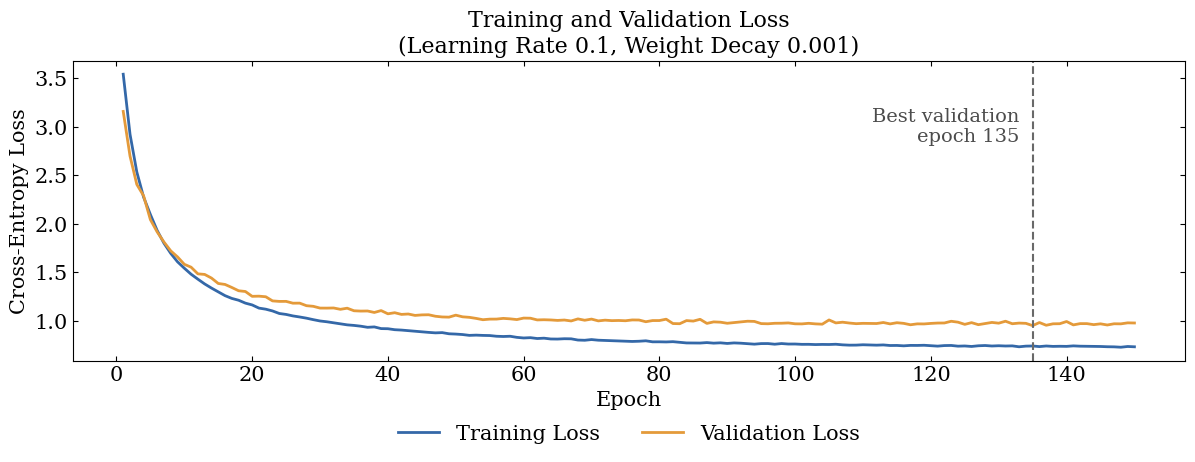

Final training loss = 0.7328, final validation loss = 0.9782


In [14]:
# Visualize training history
plt.figure(figsize=(12.2, 5.0))
epochs = np.arange(1, len(train_history) + 1)

plt.plot(epochs, train_history, '-', color='C0', label='Training Loss', linewidth=2)
plt.plot(epochs, val_history, '-', color='C1', label='Validation Loss', linewidth=2)

plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('Training and Validation Loss\n(Learning Rate 0.1, Weight Decay 0.001)')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

# Mark the epoch with the lowest validation loss
min_val_idx = np.argmin(val_history)
plt.axvline(x=min_val_idx+1, color='dimgray', linestyle='--')
plt.text(min_val_idx-1, max(val_history)*0.9, f'Best validation\nepoch {min_val_idx+1}',
         ha='right', fontsize=14, alpha=0.7)

plt.tight_layout()
plt.show()

print(f"Final training loss = {train_history[-1]:.4f}, final validation loss = {val_history[-1]:.4f}")

Both losses fall quickly during the first 20 epochs. The training loss then keeps falling slowly, and the validation loss flattens after about 60 epochs with small fluctuations. The dashed line marks the lowest validation loss, which differs little from the values at the later epochs. The validation loss stays above the training loss, because the weights fit the fit objects better than the validation objects.

## Hyperparameter Optimization

As in Tutorial 7, we choose the hyperparameters with a grid search on the validation objects. The learning rate $\eta$ sets the step size. The weight decay $\lambda$ sets the strength of the L2 regularization. It trades a good fit of the fit objects against small weights that generalize better.

We fix the batch size at 32 and the number of epochs at 150 for all models. We train a model for each combination of the learning rate and the weight decay. We trace the validation loss after every epoch and keep the weights with the lowest validation loss. We select the combination with the lowest validation loss. We now implement the grid search.

In [15]:
# Define hyperparameter grid
learning_rates = [0.01, 0.05, 0.1, 0.5, 1.0]
weight_decays = [0.0, 0.0001, 0.0005, 0.001, 0.005]

# Train one model for each pair on the fit objects, and score the lowest validation loss of its training
val_loss_matrix = np.zeros((len(learning_rates), len(weight_decays)))
best_val_loss = float('inf')
for i, lr in enumerate(learning_rates):
    for j, wd in enumerate(weight_decays):
        _, W_best, _, val_hist = train_multiclass_logistic_regression(
            X_fit, y_fit, X_val, y_val,
            num_classes=num_classes,
            num_epochs=150,
            batch_size=32,
            learning_rate=lr,
            weight_decay=wd,
            seed=42
        )
        val_loss_matrix[i, j] = min(val_hist)

        # Keep the pair with the lowest validation loss, with its best weights
        if min(val_hist) < best_val_loss:
            best_val_loss = min(val_hist)
            best_params = {'learning_rate': lr, 'weight_decay': wd}
            best_epoch = int(np.argmin(val_hist)) + 1  # epoch of the lowest validation loss
            W_final = W_best

print(f"Best: learning rate {best_params['learning_rate']}, weight decay {best_params['weight_decay']}")
print(f"Lowest validation loss {best_val_loss:.4f} at epoch {best_epoch}")

Best: learning rate 0.1, weight decay 0.0
Lowest validation loss 0.7242 at epoch 141


We show the lowest validation loss of every combination as a heatmap, and we mark the best combination with a blue frame.

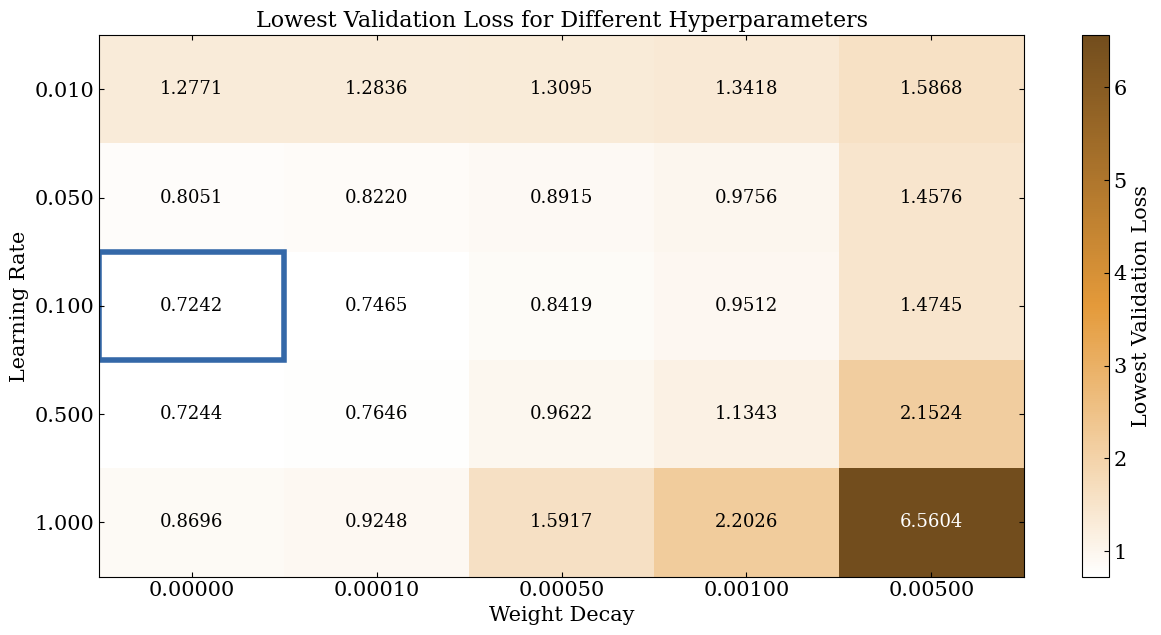

In [16]:
def plot_heatmap(matrix, cmap, label, annotations, annot_size=13):
    """Draw a matrix as colored cells with a text in each cell and a color bar."""
    image = plt.imshow(matrix, cmap=cmap, aspect='auto')
    plt.colorbar(image, label=label)

    # Text in each cell, white on dark cells and black on light cells
    cell_colors = image.cmap(image.norm(matrix))
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            r, g, b = cell_colors[row, col, :3]
            dark = 0.299 * r + 0.587 * g + 0.114 * b < 0.408
            plt.text(col, row, annotations[row][col], ha='center', va='center',
                     color='white' if dark else 'black', fontsize=annot_size)

# Draw the heatmap
plt.figure(figsize=(12.9, 6.6))
plot_heatmap(val_loss_matrix, 'book_orange', 'Lowest Validation Loss',
             [[f'{value:.4f}' for value in row] for row in val_loss_matrix])
plt.xticks(range(len(weight_decays)), [f'{wd:.5f}' for wd in weight_decays])
plt.yticks(range(len(learning_rates)), [f'{lr:.3f}' for lr in learning_rates])

plt.xlabel('Weight Decay')
plt.ylabel('Learning Rate')
plt.title('Lowest Validation Loss for Different Hyperparameters')

# Mark the best combination with a blue frame
best_lr_idx = learning_rates.index(best_params['learning_rate'])
best_wd_idx = weight_decays.index(best_params['weight_decay'])
plt.gca().add_patch(plt.Rectangle((best_wd_idx - 0.5, best_lr_idx - 0.5), 1, 1,
                                  fill=False, edgecolor='C0', linewidth=4))

plt.tight_layout()
plt.show()

The heatmap shows that the best learning rate is 0.1 and the best weight decay is 0.0.

**Learning rate effects.** The result gets much better when the learning rate increases from 0.01 to 0.1, and the best value is 0.1. The learning rate 0.5 gives nearly the same loss, and 1.0 gives a higher loss. The model benefits from large optimization steps up to a point, and then the training becomes noisy.

**Regularization effects.** Weight decay hurts the result at all learning rates. The degradation is very large at the high learning rates. For this model, the additional L2 penalty does not help.

## Model Evaluation: Confusion Matrix and Accuracy

The best weights of the best combination are our final model. We test it on the test objects, which took no part in any choice. As in Tutorial 7, a confusion matrix counts the objects of each true class that the model predicts as each class. With 50 classes it shows which classes the model gets right and which classes it confuses. We compute the confusion matrix and the metrics that follow from it.

## Understanding Classification Metrics

The accuracy is the fraction of correct predictions over all classes. Tutorial 7 defined the recall and the precision for a positive class. With many classes no single class is the positive class, so we compute them for every class $k$ in turn. Class $k$ is then the positive class, and all other classes together are the negative class.

$\text{TP}_k$ is the number of objects of class $k$ that the model predicts as class $k$. $\text{FP}_k$ is the number of objects of other classes that the model predicts as class $k$. $\text{FN}_k$ is the number of objects of class $k$ that the model predicts as another class.

The **recall** of class $k$ is the fraction of the objects of class $k$ that the model finds,

$$\text{Recall}_k = \frac{\text{TP}_k}{\text{TP}_k + \text{FN}_k}.$$

The **precision** of class $k$ is the fraction of the objects that the model predicts as class $k$ and that truly belong to it,

$$\text{Precision}_k = \frac{\text{TP}_k}{\text{TP}_k + \text{FP}_k}.$$

A low recall means that the model misses many objects of the class. A low precision means that its predictions of the class contain many wrong objects. For many classes we average the two over the classes. The per-class values show which types of objects the model gets right and which types cause confusion. We now code the prediction and the confusion matrix.

In [17]:
def predict_classes(X, W):
    """Predict the class with the largest probability for each row of X."""
    logits = X @ W.T
    probs = softmax(logits)

    # Index of the largest probability in each row
    predictions = np.argmax(probs, axis=1)
    return predictions

def compute_confusion_matrix(y_true, y_pred, num_classes):
    """Compute the confusion matrix. Rows are true classes and columns are predicted classes."""
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)  # count each pair of true class and predicted class
    return cm

We also code the accuracy and the metrics of each class, which follow from the confusion matrix.

In [18]:
def calculate_metrics(cm):
    """Calculate the accuracy and the precision and the recall of each class from the confusion matrix."""
    tp = np.diag(cm)  # objects of each class that are predicted as that class
    fp = cm.sum(axis=0) - tp  # objects of other classes that are predicted as the class
    fn = cm.sum(axis=1) - tp  # objects of the class that are predicted as other classes

    # Precision and recall of each class, zero where the denominator is zero
    precision = np.divide(tp, tp + fp, out=np.zeros(len(cm)), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros(len(cm)), where=(tp + fn) > 0)

    # Collect the metrics in a dictionary
    return {
        'accuracy': tp.sum() / cm.sum(),
        'precision': precision,
        'recall': recall,
        'avg_precision': np.mean(precision),
        'avg_recall': np.mean(recall)
    }

We predict the class of every test object with the final model, and we compute the confusion matrix and the metrics.

In [19]:
# Make predictions on the test set, and compute the confusion matrix and the metrics
y_test_pred = predict_classes(X_test, W_final)
cm = compute_confusion_matrix(y_test, y_test_pred, num_classes)
metrics = calculate_metrics(cm)

print(f"Accuracy = {metrics['accuracy']:.4f}")
print(f"Average precision = {metrics['avg_precision']:.4f}, average recall = {metrics['avg_recall']:.4f}")

Accuracy = 0.7617
Average precision = 0.7842, average recall = 0.7663


The model classifies about three of four test objects correctly. Random guessing among 50 classes gives an accuracy of about 2 percent. The average recall is close to the accuracy, because most classes have the same size of 64 objects. The average precision is a little higher than the average recall.

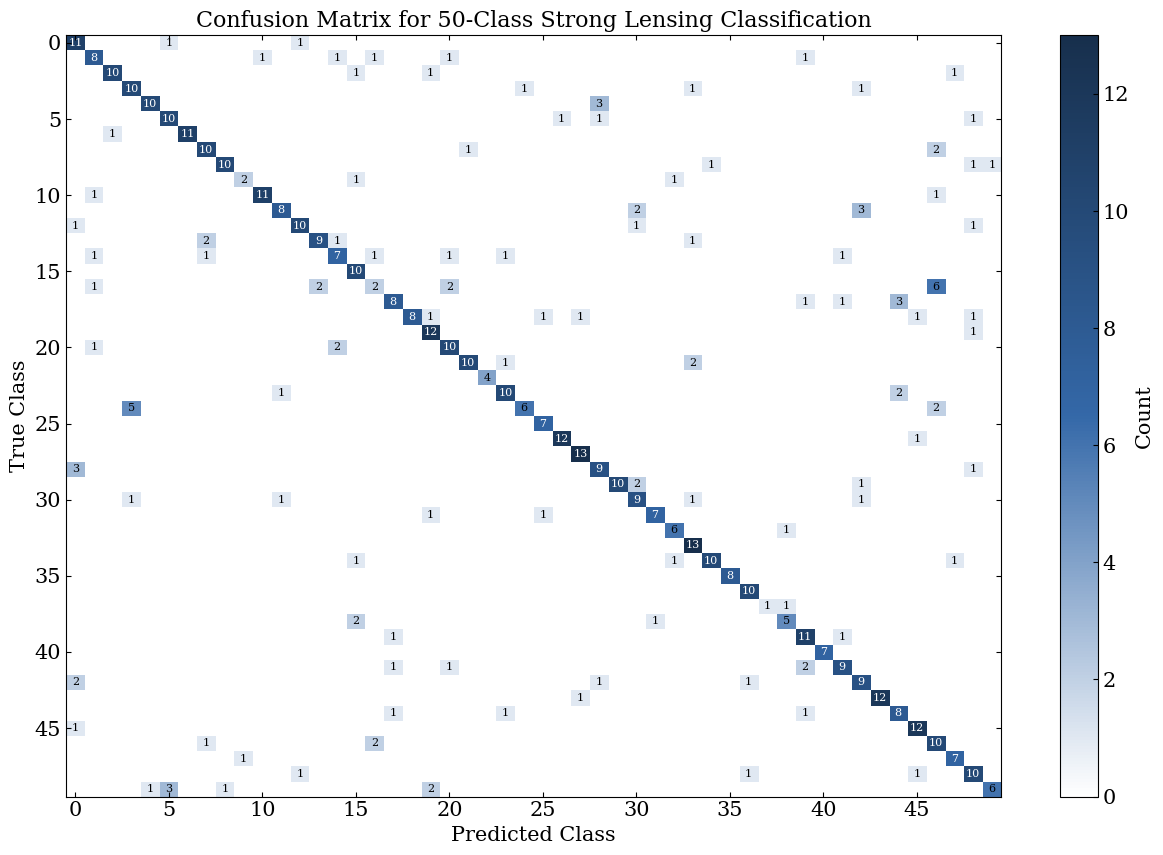

In [20]:
# Plot the confusion matrix as a heatmap with the counts in the cells, zeros left blank, and a tick label for every fifth class
plt.figure(figsize=(12.7, 8.8))
plot_heatmap(cm, 'book_blue', 'Count', [[str(value) if value > 0 else '' for value in row] for row in cm], annot_size=8)
plt.xticks(range(0, cm.shape[1], 5))
plt.yticks(range(0, cm.shape[0], 5))

plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix for 50-Class Strong Lensing Classification')

plt.tight_layout()
plt.show()

## Understanding Classification Errors

The confusion matrix shows which classes our model finds hard to distinguish. When we analyze the most common misclassifications, we can learn about the limits of our feature representation and find possible improvements.

The strong diagonal of the confusion matrix shows a good overall accuracy. The off-diagonal elements show systematic confusions, and some classes are nearly perfect while others have large errors.

We now identify the three worst-performing classes and examine which classes they are confused with.

In [21]:
# The three classes with the lowest recall
worst_classes = np.argsort(metrics['recall'])[:3]

worst_pairs = []
for n, idx in enumerate(worst_classes):
    # The wrong class with the most predictions for this true class
    confusion_row = cm[idx].copy()
    confusion_row[idx] = 0  # Exclude correct predictions
    most_confused = np.argmax(confusion_row)  # Index of the wrong class with the most predictions
    worst_pairs.append((idx, most_confused))

    # A line separates the pairs of classes
    if n > 0:
        print('-' * 60)

    # One description belongs to each class
    print(f"Class {idx}: recall {metrics['recall'][idx]:.3f}, most confused with class "
          f"{most_confused} (count {confusion_row[most_confused]})")
    for class_id in (idx, most_confused):
        description = images_df.loc[images_df['label'] == class_id, 'description'].iloc[0]
        print(f"- {class_id}: {description}")

Class 16: recall 0.154, most confused with class 46 (count 6)
- 16: Colorful, blurry nebulous structures with blue-orange contrast
- 46: Extremely blurry, low-resolution red-blue color patches
------------------------------------------------------------
Class 24: recall 0.462, most confused with class 3 (count 5)
- 24: Blurry blue-orange diffuse deep-field objects
- 3: Blurry multicolored cosmic structures with elongated features
------------------------------------------------------------
Class 49: recall 0.462, most confused with class 5 (count 3)
- 49: Diffuse, centrally-bright elliptical galaxies
- 5: Compact elliptical galaxies with bright cores


We show four random objects of each of these classes, and four of the class that it is confused with. Each row is one pair.

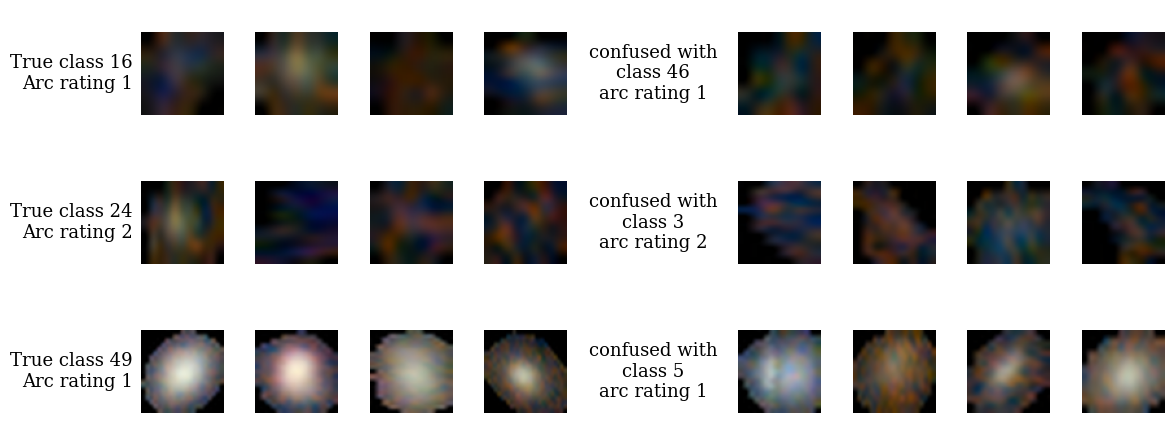

In [22]:
# One row for each pair, with the true class on the left and the confused class on the right
fig, axes = plt.subplots(3, 9, figsize=(12.0, 4.7), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1.3, 1, 1, 1, 1]})

# Fill each row with the objects of the pair and the labels of the classes
for row, (true_class, confused_class) in enumerate(worst_pairs):
    for side, class_id in enumerate((true_class, confused_class)):
        class_data = images_df[images_df['label'] == class_id]

        # Four random objects of the class
        samples = class_data.sample(min(4, len(class_data)), random_state=0)
        for j, (_, sample_row) in enumerate(samples.iterrows()):
            axes[row, 5 * side + j].imshow(sample_row['image'])

    # The rating is the same for all objects of a class
    rating_true = images_df.loc[images_df['label'] == true_class, 'arc_rating'].iloc[0]
    rating_confused = images_df.loc[images_df['label'] == confused_class, 'arc_rating'].iloc[0]
    axes[row, 0].text(-0.1, 0.5, f'True class {true_class}\nArc rating {rating_true:.0f}',
                      transform=axes[row, 0].transAxes, fontsize=13,
                      verticalalignment='center', horizontalalignment='right')
    axes[row, 4].text(0.5, 0.5, f'confused with\nclass {confused_class}\narc rating {rating_confused:.0f}',
                      fontsize=13, verticalalignment='center', horizontalalignment='center')

for ax in axes.flatten():
    ax.axis('off')

plt.tight_layout()
plt.show()

### Misclassifications

The visual comparison shows that the model confuses classes that look alike.

**Hard cases.** The first two pairs (classes 16 and 46, and classes 24 and 3) show low-contrast, diffuse structures with subtle color variations. These objects are hard to distinguish. The classes of a pair have the same low arc rating, 1 for the first pair and 2 for the second. The objects therefore have probably no gravitational arcs. The confusion here may come from an ambiguity of the data and not from a failure of the approach.

**Similar morphologies.** The third pair (classes 49 and 5) shows round elliptical galaxies with bright cores. The two classes differ mainly in how compact the galaxy is and how bright its core is. These are small differences, and the objects of the two classes overlap.

**Limits of the approach.** The confusion of classes with subtle differences suggests that the embeddings may not encode fine details of the appearance. The model behind the embeddings trained mostly on everyday photographs, so we apply it in a change of domain. Multi-class logistic regression also separates the classes with linear boundaries (Section 8.4), which may miss fine differences.

In all three pairs, the confused classes have the same arc rating. This suggests that the embeddings encode the presence or absence of lensing features at a basic level. For many astronomical applications, finding the presence of strong lensing matters more than separating subtle morphological types.

## Summary

This tutorial extended the binary logistic regression of Chapter 7 to multi-class classification. We turned images of astronomical objects into features with a pre-trained network. We trained a classifier that gives new images the labels of a labeled sample. The classifier labels most test objects correctly.

Our main lessons follow.

1. **From two classes to many.** The softmax function generalizes the sigmoid function to one probability for each class. We implemented it in a numerically stable way. The multi-class cross-entropy loss has a gradient of the same form as in the binary case, the prediction error times the features. Matrix operations then make the training efficient.
2. **Features from a pre-trained network.** Embeddings turn images into compact numerical features that carry visual and semantic information. A linear model can then separate the classes, and a two-dimensional map of the embeddings shows how the objects group.
3. **Training and hyperparameters.** As in Tutorial 7, mini-batch stochastic gradient descent trains the model. Weight decay penalizes large weights, and we chose it and the learning rate with a grid search on validation objects. We kept the weights with the lowest validation loss and scored this final model on test objects.
4. **Evaluation with many classes.** The confusion matrix and the recall and precision of each class show more than the accuracy. They reveal which classes the model confuses.

Multi-class classification is common in astronomy, because objects fall into many types and not into two. Multi-class logistic regression on pre-trained features gives a principled baseline that needs little computing time. We can evaluate more complex methods against it.